# 01_eda: Exploratory Data Analysis, MovieLens 25M

CO5135 Big Data mini-project (P1.2).

**Input:** output of notebook `00_prepare_data` (Add Input > Your Work > `00_prepare_data`).

**Output (in `results/`):**

1. `eda_rating_distribution.png`: distribution of rating values
2. `eda_longtail_movies.png`: long-tail, cumulative share of ratings by movie popularity
3. `eda_ratings_per_user.png`: number of ratings per user
4. `eda_subset_growth.png`: number of movies and item pairs as data grows (motivation for LSH)
5. `eda_summary.csv`: key numbers for the report

In [17]:
# ===== SETUP =====
import os, glob, time
!pip install -q pyspark

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.master("local[*]")
         .config("spark.driver.memory", "20g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

# Tim thu muc data cua 00_prepare_data (tu dong, khong can go path)
hits = sorted(glob.glob("/kaggle/input/**/ratings.parquet", recursive=True)) or \
       sorted(glob.glob("data/ratings.parquet"))
assert hits, "Khong thay ratings.parquet. Kiem tra da Add Input output cua 00_prepare_data chua."
DATA = os.path.dirname(hits[0])
SUBSETS_CSV = (glob.glob(os.path.join(os.path.dirname(DATA), "results", "subsets.csv"))
               or glob.glob("/kaggle/input/**/subsets.csv", recursive=True))[0]
os.makedirs("results", exist_ok=True)
print("DATA:", DATA)
print("SUBSETS_CSV:", SUBSETS_CSV)

ratings = spark.read.parquet(os.path.join(DATA, "ratings.parquet"))
print("So rating:", ratings.count())

DATA: /kaggle/input/notebooks/minhphamcompcsc/00-prepare-data/data
SUBSETS_CSV: /kaggle/input/notebooks/minhphamcompcsc/00-prepare-data/results/subsets.csv
So rating: 25000095


In [18]:
# ===== Style chung cho bieu do (dung cho report, nen sang) =====
BLUE = "#2a78d6"        # mau chinh cho 1 chuoi du lieu
BLUE_LIGHT = "#9ec5f4"
INK = "#0b0b0b"; INK2 = "#52514e"; MUTED = "#898781"; GRID = "#e6e5e0"; SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

def save(fig, name):
    path = f"results/{name}.png"
    fig.savefig(path)
    print("Saved", path)

## 1. Aggregate with Spark

In [19]:
t0 = time.time()
rating_dist = ratings.groupBy("rating").count().orderBy("rating").toPandas()
per_movie = ratings.groupBy("movieId").count().toPandas()["count"].sort_values(ascending=False).to_numpy()
per_user = ratings.groupBy("userId").count().toPandas()["count"].to_numpy()
mean_rating = ratings.agg(F.avg("rating")).first()[0]
subsets = pd.read_csv(SUBSETS_CSV)
print(f"Aggregation: {time.time() - t0:.1f}s")
print(f"So phim co rating: {len(per_movie):,}  |  So user: {len(per_user):,}")

Aggregation: 4.3s
So phim co rating: 59,047  |  So user: 162,541


## 2. Rating distribution

Saved results/eda_rating_distribution.png


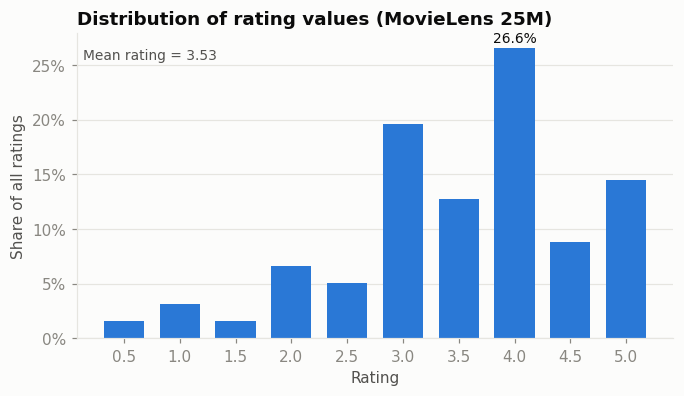

In [20]:
pct = rating_dist["count"] / rating_dist["count"].sum() * 100
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(rating_dist["rating"].astype(str), pct, color=BLUE, width=0.72)
top = pct.idxmax()
ax.annotate(f"{pct[top]:.1f}%", (top, pct[top]), xytext=(0, 4), textcoords="offset points",
            ha="center", color=INK, fontsize=9)
ax.set_title("Distribution of rating values (MovieLens 25M)")
ax.set_xlabel("Rating")
ax.set_ylabel("Share of all ratings")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.text(0.01, 0.95, f"Mean rating = {mean_rating:.2f}", transform=ax.transAxes,
        ha="left", va="top", color=INK2, fontsize=9)
save(fig, "eda_rating_distribution"); plt.show()

## 3. Long-tail: how concentrated are ratings on popular movies?

Saved results/eda_longtail_movies.png


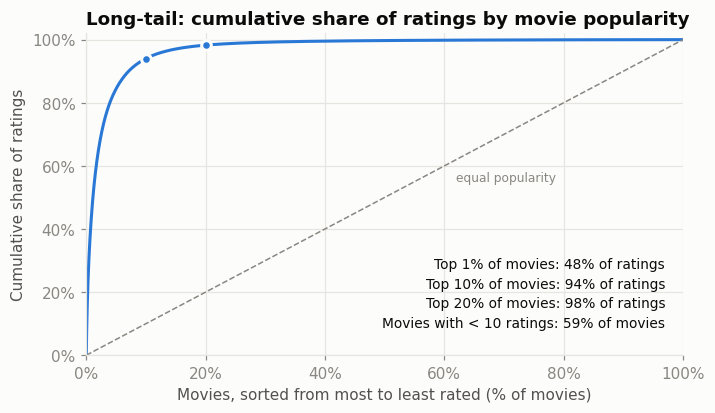

Top 1% phim: 47.6% rating | Top 10%: 94.0% | Top 20%: 98.3%
Phim co < 10 rating: 58.8% so phim


In [21]:
cum_share = np.cumsum(per_movie) / per_movie.sum() * 100
movie_pct = np.arange(1, len(per_movie) + 1) / len(per_movie) * 100

def share_of_top(p):
    k = max(1, int(round(len(per_movie) * p / 100)))
    return cum_share[k - 1]

top1, top10, top20 = share_of_top(1), share_of_top(10), share_of_top(20)
lt10 = (per_movie < 10).mean() * 100

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(movie_pct, cum_share, color=BLUE, linewidth=2)
ax.plot([0, 100], [0, 100], color=MUTED, linewidth=1, linestyle="--")
ax.text(62, 55, "equal popularity", color=MUTED, fontsize=8, rotation=0)
for p, s in [(10, top10), (20, top20)]:
    ax.scatter([p], [s], s=40, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
ax.text(97, 8, f"Top 1% of movies: {top1:.0f}% of ratings\n"
               f"Top 10% of movies: {top10:.0f}% of ratings\n"
               f"Top 20% of movies: {top20:.0f}% of ratings\n"
               f"Movies with < 10 ratings: {lt10:.0f}% of movies",
        ha="right", va="bottom", color=INK, fontsize=9, linespacing=1.5)
ax.set_title("Long-tail: cumulative share of ratings by movie popularity")
ax.set_xlabel("Movies, sorted from most to least rated (% of movies)")
ax.set_ylabel("Cumulative share of ratings")
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
save(fig, "eda_longtail_movies"); plt.show()

print(f"Top 1% phim: {top1:.1f}% rating | Top 10%: {top10:.1f}% | Top 20%: {top20:.1f}%")
print(f"Phim co < 10 rating: {lt10:.1f}% so phim")

## 4. Ratings per user

Saved results/eda_ratings_per_user.png


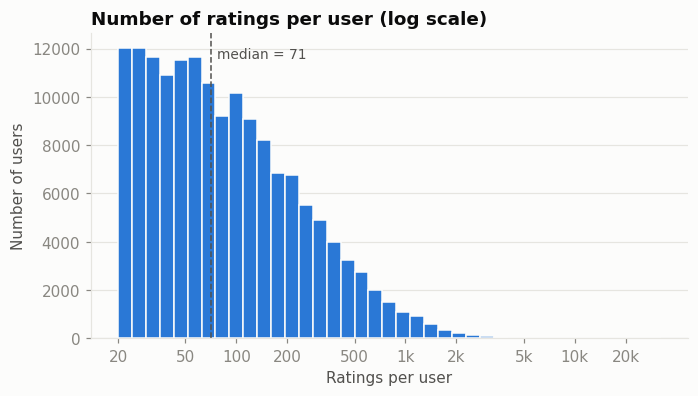

Rating/user: min 20, median 71, mean 154, max 32,202


In [22]:
bins = np.logspace(np.log10(per_user.min()), np.log10(per_user.max()), 40)
med_u = np.median(per_user)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(per_user, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.axvline(med_u, color=INK2, linewidth=1, linestyle="--")
ax.text(med_u * 1.08, ax.get_ylim()[1] * 0.92, f"median = {med_u:.0f}", color=INK2, fontsize=9)
ax.set_xscale("log")
ticks = [t for t in [20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000]
         if per_user.min() <= t <= per_user.max()]
ax.set_xticks(ticks)
ax.xaxis.set_minor_locator(mtick.NullLocator())
ax.set_title("Number of ratings per user (log scale)")
ax.set_xlabel("Ratings per user")
ax.set_ylabel("Number of users")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k" if v >= 1000 else f"{v:.0f}"))
ax.grid(axis="x", visible=False)
save(fig, "eda_ratings_per_user"); plt.show()

print(f"Rating/user: min {per_user.min()}, median {med_u:.0f}, mean {per_user.mean():.0f}, max {per_user.max():,}")

## 5. Subset growth: why brute-force does not scale

Brute-force item-item similarity compares every pair of movies: about n² / 2 pairs.

Saved results/eda_subset_growth.png


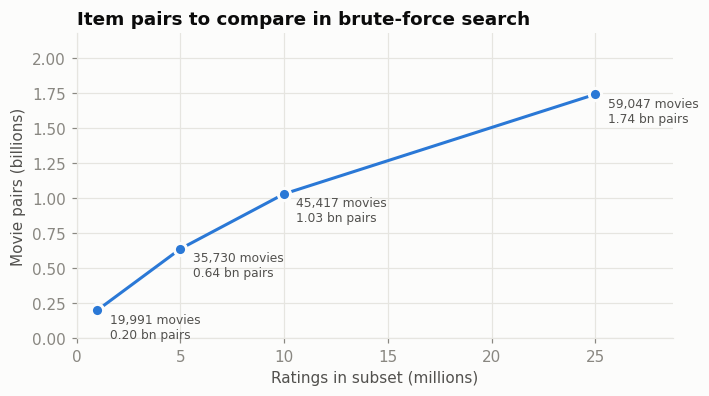

,subset,ratings,movies,pairs_bn
0,1m,999935,19991,0.199820
1,5m,4999764,35730,0.638316
2,10m,9999663,45417,1.031352
3,25m,25000095,59047,1.743274


In [23]:
s = subsets.copy()
s["pairs_bn"] = s["movies"].astype(float) ** 2 / 2 / 1e9     # so cap phim (ty)
s["ratings_m"] = s["ratings"] / 1e6
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(s["ratings_m"], s["pairs_bn"], color=BLUE, linewidth=2, marker="o", markersize=8,
        markeredgecolor=SURFACE, markeredgewidth=2)
for _, r in s.iterrows():
    ax.annotate(f"{r['movies']:,.0f} movies\n{r['pairs_bn']:.2f} bn pairs", (r["ratings_m"], r["pairs_bn"]),
                xytext=(8, -18), textcoords="offset points", color=INK2, fontsize=8)
ax.set_title("Item pairs to compare in brute-force search")
ax.set_xlabel("Ratings in subset (millions)")
ax.set_ylabel("Movie pairs (billions)")
ax.set_xlim(0, s["ratings_m"].max() * 1.15); ax.set_ylim(0, s["pairs_bn"].max() * 1.25)
save(fig, "eda_subset_growth"); plt.show()
s[["subset", "ratings", "movies", "pairs_bn"]]

## 6. Summary numbers for the report

In [24]:
summary = pd.DataFrame([
    ("ratings", int(per_user.sum())),
    ("users", len(per_user)),
    ("movies_with_ratings", len(per_movie)),
    ("mean_rating", round(mean_rating, 3)),
    ("most_common_rating", float(rating_dist.loc[rating_dist["count"].idxmax(), "rating"])),
    ("ratings_per_user_min", int(per_user.min())),
    ("ratings_per_user_median", float(med_u)),
    ("ratings_per_user_max", int(per_user.max())),
    ("ratings_per_movie_median", float(np.median(per_movie))),
    ("ratings_per_movie_max", int(per_movie.max())),
    ("top1pct_movies_share_pct", round(top1, 1)),
    ("top10pct_movies_share_pct", round(top10, 1)),
    ("top20pct_movies_share_pct", round(top20, 1)),
    ("movies_lt10_ratings_pct", round(lt10, 1)),
], columns=["metric", "value"], dtype=object)
summary.to_csv("results/eda_summary.csv", index=False)
summary

,metric,value
0,ratings,25000095
1,users,162541
2,movies_with_ratings,59047
3,mean_rating,3.534
4,most_common_rating,4.0
5,ratings_per_user_min,20
6,ratings_per_user_median,71.0
7,ratings_per_user_max,32202
8,ratings_per_movie_median,6.0
9,ratings_per_movie_max,81491
